# 02 · Benchmark: plain RAG vs agentic RAG vs CAG

Every one of the 30 test questions (`data/testset.json`) was run through all three strategies by `python -m app.benchmark run`. Each answer was then graded against the hand-checked reference by `python -m app.benchmark judge`.

| strategy | what it does |
|---|---|
| **plain RAG** | search once (4 chunks), answer |
| **agentic RAG** | route → search → grade → rewrite and retry (max 2) → answer |
| **CAG** | pick 1-2 papers, put them in the prompt whole, answer |

**Read the numbers with care:**
- **30 questions, one run each.** One question is 3.3 percentage points, so small gaps are noise (section 6 puts error bars on them).
- **Latency comes from the free tier**, which varies over the day. Medians are more trustworthy than means. The very first question also paid one-time start-up costs (loading the index, opening API clients).
- Answers were generated by `gemini-3.5-flash-lite`. They were graded by a different model, `gemini-3.1-flash-lite`, and **every verdict was then checked by hand** (section 1).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..")
B = ROOT / "data" / "benchmark"
read = lambda p: [json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l]

tests = pd.DataFrame(json.loads((ROOT / "data" / "testset.json").read_text(encoding="utf-8")))
df = (pd.DataFrame(read(B / "runs.jsonl"))
      .merge(pd.DataFrame(read(B / "judgments.jsonl")), on=["id", "strategy"], how="left")
      .merge(tests[["id", "type", "question", "expected_answer"]], on="id"))

ORDER = ["plain_rag", "agentic_rag", "cag"]
NAMES = {"plain_rag": "Plain RAG", "agentic_rag": "Agentic RAG", "cag": "CAG"}
# One fixed color per strategy in every chart (validated palette, slots 1-3).
COLOR = {"plain_rag": "#2a78d6", "agentic_rag": "#eb6834", "cag": "#1baf7a"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "text.color": INK, "font.size": 10})

# Human audit: every verdict was read against the reference; disagreements
# are stored as overrides. Final scores use the audited verdict.
overrides = pd.DataFrame(json.loads((B / "audit_overrides.json").read_text(encoding="utf-8")))
df["judge_verdict"] = df.verdict
for o in overrides.itertuples():
    df.loc[(df.id == o.id) & (df.strategy == o.strategy), "verdict"] = o.verdict

df["correct"] = (df.verdict == "correct").astype(int)
df["partial"] = (df.verdict == "partial").astype(int)
expected = len(tests) * len(ORDER)
print(f"{len(df)} of {expected} runs present, {df.verdict.notna().sum()} judged")
assert len(df) == expected and df.verdict.notna().all(), "benchmark incomplete: rerun run/judge"


90 of 90 runs present, 90 judged


## 1 · Can we trust the judge?

An LLM judge is fast and consistent, but it's a model too. Known risks: **leniency** toward fluent answers, **self-preference** (a model favouring its own outputs), and misreading partial answers.

**What happened here:** the planned judge, `gemini-3.5-flash`, allows only 20 free requests per day. It graded 20 answers and was then blocked. The full run used `gemini-3.1-flash-lite` instead: still a *different* model from the one that wrote the answers, but smaller. To compensate:
- **Bare refusals are graded by a rule, not the LLM:** "I don't know" is correct exactly when the question is out of scope.
- **Every one of the 90 verdicts was read by a human** against the reference answer. Disagreements are stored in `data/benchmark/audit_overrides.json`, and the final scores use the human verdict.
- **The 20 grades from the bigger judge** give a second opinion on the smaller one.

In [2]:
llm_judged = df[df.judge != "rule"]
agree = (df.verdict == df.judge_verdict).sum()
print(f"graded by rule: {(df.judge == 'rule').sum()}   graded by LLM: {len(llm_judged)}")
print(f"judge agrees with human audit: {agree}/{len(df)} ({agree / len(df):.0%})")

flash = pd.DataFrame(read(B / "judgments_flash_sample.jsonl"))[["id", "strategy", "verdict"]]
both = df.merge(flash, on=["id", "strategy"], suffixes=("", "_flash"))
print(f"gemini-3.5-flash vs human on its {len(both)} grades: "
      f"{(both.verdict_flash == both.verdict).sum()}/{len(both)} agree")
print(f"gemini-3.1-flash-lite vs human on the same {len(both)}: "
      f"{(both.judge_verdict == both.verdict).sum()}/{len(both)} agree\n")
pd.set_option("display.max_colwidth", 160)
overrides.rename(columns={"verdict": "human verdict"})

graded by rule: 17   graded by LLM: 73
judge agrees with human audit: 88/90 (98%)
gemini-3.5-flash vs human on its 20 grades: 20/20 agree
gemini-3.1-flash-lite vs human on the same 20: 18/20 agree



,id,strategy,human verdict,reason
0,q01,plain_rag,partial,Names BART but says the parameter count is not in its context; the reference requires ~400M. The judge rated it correct; gemini-3.5-flash rated it partial.
1,q06,agentic_rag,partial,Gives the 0.77B size but says the model is not named; the reference requires T5-large. The judge rated it correct; gemini-3.5-flash rated it partial.


**Reading this:** both disagreements go the same way: the small judge called a **half-right** answer *correct*, and the bigger judge had caught both. That's the known leniency risk of smaller judges. A ~2% error rate is small next to the gaps below, but it's why the numbers use the audited verdicts.

## 2 · Headline numbers

In [3]:
PRICE_IN, PRICE_OUT = 0.30, 2.50   # $ per 1M tokens, gemini-3.5-flash-lite list price (third-party listing, Oct 2026)

def summarize(g):
    return pd.Series({
        "correct %": 100 * g.correct.mean(),
        "correct+partial %": 100 * (g.correct + g.partial).mean(),
        "median latency s": g.latency_s.median(),
        "p90 latency s": g.latency_s.quantile(0.9),
        "LLM calls / q": g.llm_calls.mean(),
        "input tokens / q": g.input_tokens.mean(),
        "cached input %": 100 * g.cached_tokens.sum() / max(g.input_tokens.sum(), 1),
        "$ per 1k questions": 1000 * (g.input_tokens.mean() * PRICE_IN
                                      + g.output_tokens.mean() * PRICE_OUT) / 1e6,
        "questions retried %": 100 * (g.retries > 0).mean(),
    })

summary = df.groupby("strategy").apply(summarize, include_groups=False).loc[ORDER]
summary.index = summary.index.map(NAMES)
summary.round(1)

,correct %,correct+partial %,median latency s,p90 latency s,LLM calls / q,input tokens / q,cached input %,$ per 1k questions,questions retried %
strategy,,,,,,,,,
Plain RAG,66.7,76.7,1.8,2.6,1.0,1084.5,0.0,0.5,0.0
Agentic RAG,80.0,86.7,3.2,7.8,2.9,2780.8,0.0,2.0,40.0
CAG,100.0,100.0,2.8,4.2,2.0,26488.8,37.9,8.3,0.0


*Cost is an estimate at list price **without** the cache discount, so CAG's real cost would be lower by roughly its cached share. Embedding calls (a few hundred tokens per search) aren't included. On the free tier, everything here cost $0.*

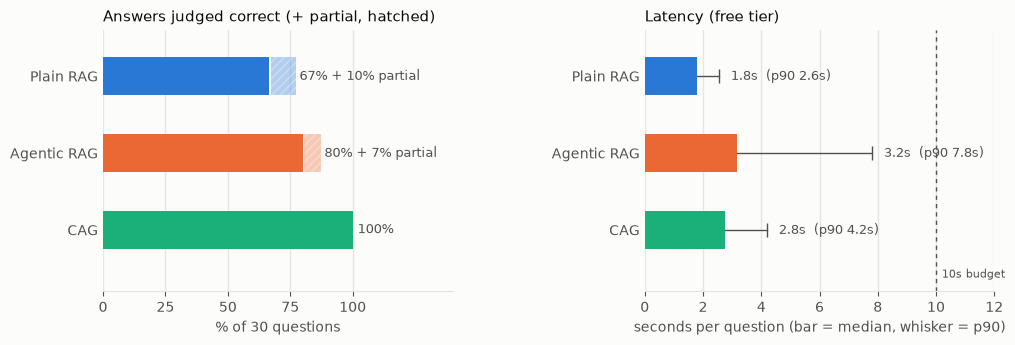

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.4), gridspec_kw={"wspace": 0.55})
y = np.arange(len(ORDER))[::-1]
s = df.groupby("strategy")

for yi, k in zip(y, ORDER):
    c, p = 100 * s.correct.mean()[k], 100 * s.partial.mean()[k]
    ax1.barh(yi, c, height=0.5, color=COLOR[k])
    ax1.barh(yi, p, left=c + 0.6, height=0.5, color=COLOR[k], alpha=0.35,
             hatch="////", edgecolor=SURFACE, linewidth=0)
    ax1.text(c + p + 2, yi, f"{c:.0f}%" + (f" + {p:.0f}% partial" if p else ""),
             va="center", color=INK2, fontsize=9)
ax1.set_yticks(y, [NAMES[k] for k in ORDER]); ax1.set_xlim(0, 140)
ax1.set_xticks([0, 25, 50, 75, 100]); ax1.set_xlabel("% of 30 questions")
ax1.set_title("Answers judged correct (+ partial, hatched)", loc="left", fontsize=11)

med, p90 = s.latency_s.median(), s.latency_s.quantile(0.9)
for yi, k in zip(y, ORDER):
    ax2.barh(yi, med[k], height=0.5, color=COLOR[k])
    ax2.plot([med[k], p90[k]], [yi, yi], color=INK2, lw=1)
    ax2.plot(p90[k], yi, "|", color=INK2, ms=10)
    ax2.text(p90[k] + 0.4, yi, f"{med[k]:.1f}s  (p90 {p90[k]:.1f}s)", va="center", color=INK2, fontsize=9)
ax2.axvline(10, color=INK2, lw=1, ls=(0, (3, 3)))
ax2.text(10.2, -0.62, "10s budget", color=INK2, fontsize=8, ha="left")
ax2.set_yticks(y, [NAMES[k] for k in ORDER]); ax2.set_xlim(0, max(p90.max() * 1.45, 12))
ax2.set_xlabel("seconds per question (bar = median, whisker = p90)")
ax2.set_title("Latency (free tier)", loc="left", fontsize=11)

for ax in (ax1, ax2):
    ax.set_ylim(-0.8, len(ORDER) - 0.4)
    ax.grid(axis="x", color=GRID, lw=1); ax.set_axisbelow(True)
    for side in ("top", "right", "left"): ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)
(ROOT / "docs").mkdir(exist_ok=True)
fig.savefig(ROOT / "docs" / "benchmark.png", dpi=160, bbox_inches="tight")
plt.show()

## 3 · Which question types does each strategy win?

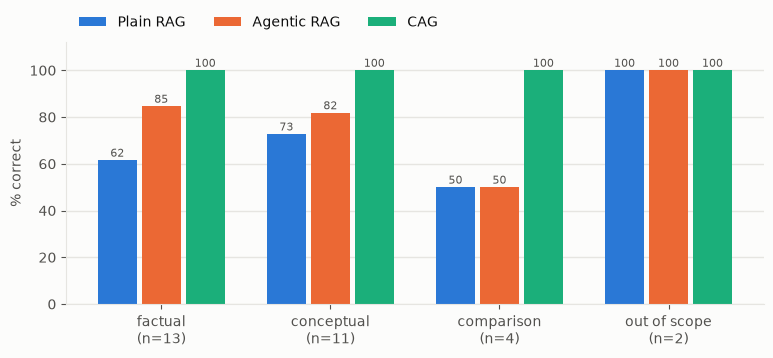

strategy,plain_rag,agentic_rag,cag
type,,,
factual,62.0,85.0,100.0
conceptual,73.0,82.0,100.0
comparison,50.0,50.0,100.0
out_of_scope,100.0,100.0,100.0


In [5]:
TYPES = ["factual", "conceptual", "comparison", "out_of_scope"]
by_type = (df.pivot_table(index="type", columns="strategy", values="correct", aggfunc="mean")
             .loc[TYPES, ORDER] * 100)
counts = tests.type.value_counts()

fig, ax = plt.subplots(figsize=(9, 3.4))
x, w = np.arange(len(TYPES)), 0.26
for i, k in enumerate(ORDER):
    vals = by_type[k].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=COLOR[k], label=NAMES[k])
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + 1.5, f"{v:.0f}", ha="center", color=INK2, fontsize=8)
ax.set_xticks(x, [f"{t.replace('_', ' ')}\n(n={counts[t]})" for t in TYPES])
ax.set_ylim(0, 112); ax.set_ylabel("% correct")
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 1.15))
ax.grid(axis="y", color=GRID, lw=1); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.show()
by_type.round(0)

Small groups: 4 comparison and 2 out-of-scope questions, so one question moves those bars by 25-50 points. Treat them as anecdotes.

## 4 · Where agentic RAG fixes plain RAG (and where it doesn't)

Same question, both strategies: a **paired** comparison, which is more informative than comparing the two averages.

In [6]:
wide = df.pivot_table(index="id", columns="strategy", values="correct")
fixed = wide[(wide.agentic_rag == 1) & (wide.plain_rag == 0)].index
broke = wide[(wide.agentic_rag == 0) & (wide.plain_rag == 1)].index
print(f"agentic right, plain wrong: {len(fixed)}   |   plain right, agentic wrong: {len(broke)}")
q = df[df.strategy == "agentic_rag"].set_index("id")
q.loc[list(fixed) + list(broke), ["question", "retries", "verdict"]].assign(
    case=["fixed by loop"] * len(fixed) + ["broken by loop"] * len(broke))

agentic right, plain wrong: 5   |   plain right, agentic wrong: 1


,question,retries,verdict,case
id,,,,
q01,"Which model does the original RAG paper use as its generator, and how many parameters does it have?",1,correct,fixed by loop
q04,Which base language models does Self-RAG use for its generator and for its critic?,1,correct,fixed by loop
q08,What model does Adaptive-RAG use for its query-complexity classifier?,1,correct,fixed by loop
q11,What three actions does ReAct's Wikipedia API support?,1,correct,fixed by loop
q14,How does CRAG decide a retrieved document is incorrect?,1,correct,fixed by loop
q06,"What model is CRAG's retrieval evaluator based on, and roughly how big is it?",0,partial,broken by loop


## 5 · Does the correction loop pay for itself?

In [7]:
ag = df[df.strategy == "agentic_rag"]
loop = ag.groupby(ag.retries.clip(upper=2)).agg(
    questions=("id", "count"), correct_pct=("correct", lambda s: 100 * s.mean()),
    median_latency_s=("latency_s", "median"), llm_calls=("llm_calls", "mean"))
loop.index.name = "rewrites"
loop.round(1)

,questions,correct_pct,median_latency_s,llm_calls
rewrites,,,,
0,18,94.4,2.8,1.9
1,8,75.0,5.6,4.0
2,4,25.0,8.0,5.5


## 6 · Are the differences real? (bootstrap)

Resample the 30 questions with replacement 10,000 times, keeping each question's pair of results together, and recompute the accuracy gap each time. If the 95% interval includes 0, the gap could be luck.

In [8]:
rng = np.random.default_rng(0)
ids = wide.index.to_numpy()
def gap_ci(a, b, n=10_000):
    d = (wide[a] - wide[b]).to_numpy()
    boots = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1) * 100
    return d.mean() * 100, *np.percentile(boots, [2.5, 97.5])
pd.DataFrame([dict(zip(["gap (pts)", "95% CI low", "95% CI high"], gap_ci(a, b)), comparison=f"{NAMES[a]} − {NAMES[b]}")
              for a, b in [("agentic_rag", "plain_rag"), ("cag", "plain_rag"), ("cag", "agentic_rag")]]
             ).set_index("comparison").round(1)

,gap (pts),95% CI low,95% CI high
comparison,,,
Agentic RAG − Plain RAG,13.3,0.0,30.0
CAG − Plain RAG,33.3,16.7,50.0
CAG − Agentic RAG,20.0,6.7,33.3


## 7 · Every answer (table view)

In [9]:
pd.set_option("display.max_colwidth", 90)
df.pivot_table(index=["id", "type"], columns="strategy", values="verdict", aggfunc="first")[ORDER]

,strategy,plain_rag,agentic_rag,cag
id,type,,,
q01,factual,partial,correct,correct
q02,factual,correct,correct,correct
q03,factual,correct,correct,correct
q04,factual,incorrect,correct,correct
q05,factual,correct,correct,correct
q06,factual,correct,partial,correct
q07,factual,correct,correct,correct
q08,factual,partial,correct,correct
q09,factual,correct,correct,correct


## 8 · Conclusion

**Result (30 questions, human-audited grades):** CAG answered **30/30** correctly, agentic RAG **24/30**, plain RAG **20/30**. All three stayed inside the 10-second budget at p90.

**When each strategy wins**

- **CAG wins when the knowledge fits in the context window.** Here each question needed 1–2 papers (~26k tokens on average), and CAG was right every time. That includes the detail questions and cross-paper comparisons that both search-based strategies missed (q17, q19, q27, q28). The price: ~25× the input tokens of plain RAG and ~10× agentic RAG (≈ $8.3 vs $2.0 vs $0.5 per 1,000 questions at list price, before the cache discount; 38% of CAG's input was served from Gemini's prompt cache). **It doesn't scale:** with thousands of documents you can't put them all in the prompt, and choosing which ones to include becomes a retrieval problem again. Its paper picker had an easy job with a 6-paper catalog.

- **Agentic RAG beats plain RAG when the first search lands on the wrong chunks.** The correction loop fixed 5 questions plain RAG got wrong or half-right (including the CRAG demo, q14) and broke 1 (q06). That's +13 points, but the 95% bootstrap interval runs from 0 to +30, so with 30 questions it's **suggestive, not proven**. Cost: ~3 LLM calls instead of 1, and +1.4 s median latency.

- **Retries have diminishing returns.** Questions answered with no rewrite were 94% correct, after one rewrite 75%, after two only 25% (1 of 4). The second retry mostly adds latency, so a cap of 1 may be the better trade-off (on only 4 questions, so worth re-testing).

- **Where search-based RAG still fails:** answers spread across a table or list (Self-RAG's reflection-token table, q17), and comparisons needing one fact from each of two papers (q27, q28). Rewriting the query didn't fix these. The natural next steps are **query decomposition** (one sub-question per paper) and table-aware chunking.

- **Plain RAG** is the cheapest and fastest (1.8 s median, ~$0.5 per 1,000 questions). It's enough when the question uses the same words as a single passage.

**Recommendation:** for a small, stable corpus like this one, **CAG**. For the usual production case, a corpus too big for the prompt, use **agentic RAG over plain RAG**, and invest next in query decomposition for comparison questions.

**Caveats:** one run per question (LLM output varies between runs); 30 questions written from the papers by the builder, which may favour single-paper facts; graded by a small LLM judge, audited by hand (98% agreement); latency measured on the free tier.
